<a href="https://colab.research.google.com/github/sabbirpuspo/PGCB-Demand-Aware-Smart-Grid-Optimization/blob/main/PGCB_Demand_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PGCB Demand Forecasting

**Working IEEE paper title:** *An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids*

**Research question for this notebook:** Can a forecasting model predict the next day's 24 hourly loads more accurately than simple historical-demand benchmarks, using only information available before that day starts?

This is a **forecasting experiment**, not the proposed optimization algorithm. The objective is to build a trustworthy forecasting input for the next phase of the study. It does not estimate actual load-shedding reductions.

**Source:** PGCB Hourly Generation Dataset (Bangladesh), UCI Machine Learning Repository, DOI [10.24432/C59P6V](https://doi.org/10.24432/C59P6V); original dataset at [UCI](https://archive.ics.uci.edu/dataset/1175/pgcb+hourly+generation+dataset+(bangladesh)). The earlier reference paper is [Islam et al. (2025)](https://doi.org/10.1007/s42488-025-00140-9).

### Experimental protocol (set before reading the results)

| Period | Purpose | Rules |
|:--|:--|:--|
| 2015-2021 | Initial model fitting | Learn relationships between historical load and next-day demand |
| Jan-Jun 2022 | Model choice | Select the lowest-MAE candidate; do not select using 2023 |
| Jan 2015-Jun 2022 | Refit after choice | Fit the fixed candidate definitions on all available earlier observations |
| Jul-Dec 2022 | Forecast-error calibration | Estimate an exploratory uncertainty margin without training on this period |
| 2023 | Final Phase 2 evaluation | Report all candidate methods, but do not change the selection rule |
| 2024-2025 | Not accessed in Phase 2 evaluation | Already examined in Phase 1; avoid further tuning on these years |

**Limitations:** The PGCB workbook records national-level demand, not consumer-level flexible loads or generator availability. The initial data screen drops irregular/duplicate timestamps and restricts modeling to complete calendar days. The error margin is a historical calibration diagnostic, **not a guaranteed prediction interval under distribution shift**. Output is saved to a new timestamped Google Drive run folder.

## 1. Libraries and environment

This cell loads the scientific-Python packages used throughout the experiment. Colab includes these packages in most current runtimes. If an import fails, install the named package in Colab and rerun this cell. A CPU runtime is sufficient; no GPU is required.

In [ ]:
import hashlib
import io
import json
import os
import platform
import shutil
import sys
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
IS_COLAB = 'google.colab' in sys.modules
print('Python:', platform.python_version())
print('Pandas:', pd.__version__)
print('Scikit-learn:', sklearn.__version__)
print('Environment:', 'Google Colab' if IS_COLAB else 'local Python')


Python: 3.13.16
Pandas: 2.2.3
Scikit-learn: 1.6.1
Environment: Google Colab


## 2. Project settings and output folder

Keep all adjustable settings here. The experiment uses the same broad demand and generation anomaly-screening limits as Phase 1; those limits are screening choices, **not** measured engineering capacities. Every run creates a distinct folder, so a previous experiment is not overwritten.

The original workbook is stored once in `MyDrive/PGCB_Demand_Optimization/data/`. Results are stored in `MyDrive/PGCB_Demand_Optimization/runs/`.

In [ ]:
USE_GOOGLE_DRIVE = True
DATASET_FILENAME = 'PGCB_date_power_demand.xlsx'
UCI_ARCHIVE_URL = (
    'https://archive.ics.uci.edu/static/public/1175/'
    'pgcb%2Bhourly%2Bgeneration%2Bdataset%2B%28bangladesh%29.zip'
)
MIN_DEMAND_MW, MAX_DEMAND_MW = 1000.0, 30000.0
MIN_GENERATION_MW, MAX_GENERATION_MW = 0.0, 30000.0

if IS_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/PGCB_Demand_Optimization')
elif IS_COLAB:
    PROJECT_DIR = Path('/content/PGCB_Demand_Optimization')
else:
    PROJECT_DIR = Path('/mnt/data/PGCB_Demand_Optimization')

DATA_DIR = PROJECT_DIR / 'data'
RUN_ID = 'phase2_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
OUT_DIR = PROJECT_DIR / 'runs' / RUN_ID
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=False)

print('Run:', RUN_ID)
print('Output:', OUT_DIR)


Mounted at /content/drive
Run: phase2_20261107T083301Z_c5a9ca
Output: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase2_20261107T083301Z_c5a9ca


## 3. Obtain the original PGCB workbook

The dataset is **not** something you need to upload to Google Drive manually. The code first checks the existing Phase 1 dataset cache. If the workbook is absent, it downloads the official UCI ZIP, extracts the Excel workbook, and saves it in the cache. It also records a SHA-256 fingerprint so reviewers can identify the exact source file used.

For local testing outside Colab, the optional `PGCB_LOCAL_XLSX` environment variable can point to a local copy. No source workbook is modified.

In [ ]:
DATA_PATH = DATA_DIR / DATASET_FILENAME
local_override = os.environ.get('PGCB_LOCAL_XLSX') if not IS_COLAB else None
if local_override:
    DATA_PATH = Path(local_override)

if not DATA_PATH.exists():
    print('Dataset cache not found. Downloading original UCI archive...')
    response = requests.get(UCI_ARCHIVE_URL, timeout=180)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        excel_members = [name for name in archive.namelist()
                         if name.lower().endswith('pgcb_date_power_demand.xlsx')]
        if len(excel_members) != 1:
            raise RuntimeError(f'Expected one PGCB workbook in the UCI archive; found {excel_members}')
        partial = DATA_DIR / (DATASET_FILENAME + '.partial')
        try:
            with archive.open(excel_members[0]) as src, partial.open('wb') as dst:
                shutil.copyfileobj(src, dst)
            partial.replace(DATA_PATH)
        finally:
            partial.unlink(missing_ok=True)

if DATA_PATH.stat().st_size < 1000:
    raise RuntimeError('The cached workbook is unexpectedly small; check the UCI download.')

source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_excel(DATA_PATH, engine='openpyxl',
                    usecols=['datetime', 'demand_mw', 'generation_mw', 'load_shedding'])
required_columns = {'datetime', 'demand_mw', 'generation_mw', 'load_shedding'}
assert required_columns.issubset(raw.columns)

print('Workbook:', DATA_PATH)
print('SHA-256:', source_sha256)
print('Total source records:', len(raw))


Workbook: /content/drive/MyDrive/PGCB_Demand_Optimization/data/PGCB_date_power_demand.xlsx
SHA-256: cd10a95b98033594b70ff176d69e9feaa2ade5f43b8ae4e5640a0f9deabc9da1
Total source records: 92650


## 4. Audit the input data and isolate valid hourly observations

The workbook contains irregular timestamps, repeated timestamps, and a few implausible numerical values. This step keeps **only data before January 2024**, rejects ambiguous duplicate-time groups, and retains uniquely timed, on-the-hour records within the predefined screening range.

We do not fill gaps using future observations or randomly split the time series. The original workbook is left untouched. A JSON audit records how many rows each quality criterion affects.

In [ ]:
working = raw.copy()
working['datetime'] = pd.to_datetime(working['datetime'], errors='coerce')
for col in ('demand_mw', 'generation_mw', 'load_shedding'):
    working[col] = pd.to_numeric(working[col], errors='coerce')

# Exclude later periods before feature generation or model fitting.
scope = working.loc[working['datetime'].lt(pd.Timestamp('2024-01-01'))].copy()
dup_group = scope['datetime'].duplicated(keep=False)
on_the_hour = scope['datetime'].dt.minute.eq(0) & scope['datetime'].dt.second.eq(0)
plausible_demand = scope['demand_mw'].between(MIN_DEMAND_MW, MAX_DEMAND_MW)
plausible_generation = scope['generation_mw'].between(MIN_GENERATION_MW, MAX_GENERATION_MW)
valid = on_the_hour & ~dup_group & plausible_demand & plausible_generation

hourly = (scope.loc[valid, ['datetime', 'demand_mw']]
          .sort_values('datetime').set_index('datetime'))
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing

hourly_day_counts = hourly.groupby(hourly.index.normalize()).size()
complete_days = hourly_day_counts[hourly_day_counts.eq(24)].index
complete = hourly.loc[hourly.index.normalize().isin(complete_days)].copy()

quality_report = {
    'source_rows': len(raw),
    'records_before_2024': len(scope),
    'duplicate_timestamp_group_rows': int(dup_group.sum()),
    'off_hour_rows': int((~on_the_hour).sum()),
    'out_of_screen_demand_rows': int((~plausible_demand).sum()),
    'out_of_screen_generation_rows': int((~plausible_generation).sum()),
    'valid_hourly_records': len(hourly),
    'complete_days': len(complete_days),
    'eligible_days_by_year_before_lag_checks': {
        str(k): int(v) for k, v in pd.Series(complete_days.year).value_counts().sort_index().items()
    },
}
(OUT_DIR / 'data_quality_report.json').write_text(json.dumps(quality_report, indent=2))
print(pd.Series({k: v for k, v in quality_report.items() if not isinstance(v, dict)}).to_string())
print('Complete days by year:', quality_report['eligible_days_by_year_before_lag_checks'])


source_rows                       92650
records_before_2024               79314
duplicate_timestamp_group_rows      785
off_hour_rows                      3649
out_of_screen_demand_rows            16
out_of_screen_generation_rows         1
valid_hourly_records              74882
complete_days                      2684
Complete days by year: {'2015': 183, '2016': 291, '2017': 265, '2018': 293, '2019': 318, '2020': 338, '2021': 343, '2022': 327, '2023': 326}


## 5. Build features that are known before the target day begins

For each target hour, the model can inspect the same clock hour **1, 2, 3, 7, or 14 days earlier**. It can also use calendar features such as hour of day and day of week. Every lag points backward in time, so no target-day measured demand enters the forecast inputs.

A day is included only when its full 24-hour demand profile and complete 1-day and 7-day reference profiles are available. Optional additional lags may be missing; their missing values will be handled by a training-fitted imputer. All candidate models use the same eligible observations.

In [ ]:
model_data = complete.rename(columns={'demand_mw': 'actual_mw'}).copy()
for days_back in (1, 2, 3, 7, 14):
    previous_hours = model_data.index - pd.Timedelta(days=days_back)
    model_data[f'lag_{days_back}d_mw'] = complete['demand_mw'].reindex(previous_hours).to_numpy()

model_data = model_data.loc[
    model_data['lag_1d_mw'].notna() & model_data['lag_7d_mw'].notna()
].copy()
model_data['date'] = model_data.index.normalize()
model_data['hour'] = model_data.index.hour
model_data['day_of_week'] = model_data.index.dayofweek
model_data['day_of_year'] = model_data.index.dayofyear
model_data['month'] = model_data.index.month
model_data['weekend'] = (model_data['day_of_week'] >= 5).astype(int)

for label, values, cycle in (
    ('hour', model_data['hour'], 24),
    ('weekday', model_data['day_of_week'], 7),
    ('year', model_data['day_of_year'], 365.25),
):
    model_data[f'{label}_sin'] = np.sin(2 * np.pi * values / cycle)
    model_data[f'{label}_cos'] = np.cos(2 * np.pi * values / cycle)

model_data['yesterday_vs_week_mw'] = model_data['lag_1d_mw'] - model_data['lag_7d_mw']
model_data['last_three_days_mean_mw'] = model_data[
    ['lag_1d_mw', 'lag_2d_mw', 'lag_3d_mw']
].mean(axis=1)

FEATURES = [
    'lag_1d_mw', 'lag_2d_mw', 'lag_3d_mw', 'lag_7d_mw', 'lag_14d_mw',
    'yesterday_vs_week_mw', 'last_three_days_mean_mw',
    'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
    'year_sin', 'year_cos', 'weekend',
]

assert model_data['actual_mw'].notna().all()
assert model_data.groupby('date').size().eq(24).all()
assert model_data.index.max() < pd.Timestamp('2024-01-01')
assert not model_data[FEATURES].isna().all(axis=1).any()
print('Eligible complete days:', model_data['date'].nunique())
print('Hours available for modeling:', len(model_data))
print('Days by year:', model_data.groupby(model_data.index.year)['date'].nunique().to_dict())


Eligible complete days: 2013
Hours available for modeling: 48312
Days by year: {2015: 98, 2016: 181, 2017: 154, 2018: 190, 2019: 245, 2020: 298, 2021: 308, 2022: 265, 2023: 274}


## 6. Chronological development and evaluation periods

We make **three non-overlapping decisions in time**:

1. Fit candidate models on observations up to December 2021.
2. Select the model using January-June 2022, then refit the fixed model definitions using all records available through June 2022.
3. Use July-December 2022 only to estimate forecast uncertainty, and evaluate the locked methods on 2023.

The time boundaries are fixed before examining the results. No data from 2024 or 2025 is loaded into this experiment.

In [ ]:
dates = model_data['date']
train_initial = model_data.loc[dates.lt('2022-01-01')].copy()
selection = model_data.loc[dates.ge('2022-01-01') & dates.lt('2022-07-01')].copy()
train_refit = model_data.loc[dates.lt('2022-07-01')].copy()
calibration = model_data.loc[dates.ge('2022-07-01') & dates.lt('2023-01-01')].copy()
validation = model_data.loc[dates.ge('2023-01-01') & dates.lt('2024-01-01')].copy()

periods = {
    'initial_train': train_initial,
    'selection_2022_H1': selection,
    'refit_through_2022_H1': train_refit,
    'calibration_2022_H2': calibration,
    'validation_2023': validation,
}
for name, frame in periods.items():
    print(f'{name:25s}: {frame["date"].nunique():4d} days / {len(frame):5d} hours')
    assert len(frame) > 0

assert train_initial['date'].max() < selection['date'].min()
assert selection['date'].max() < calibration['date'].min()
assert calibration['date'].max() < validation['date'].min()
assert train_refit['date'].max() < calibration['date'].min()


initial_train            : 1474 days / 35376 hours
selection_2022_H1        :  126 days /  3024 hours
refit_through_2022_H1    : 1600 days / 38400 hours
calibration_2022_H2      :  139 days /  3336 hours
validation_2023          :  274 days /  6576 hours


## 7. Forecasting candidates and evaluation metrics

We compare two transparent historical-demand rules against two standard regression methods. The trained methods are **forecasting candidates**, not components of an ensemble and not a claim of new algorithmic novelty.

- **Previous day:** use the same hour from yesterday.
- **Previous week:** use the same hour from seven days earlier (the Phase 1 reference forecast).
- **Ridge regression:** a regularized linear predictor using historical-load and calendar features.
- **Boosted trees:** a nonlinear predictor using the same features.

The principal model-choice metric is **mean absolute error (MAE) in MW**. RMSE, MAPE, and absolute daily peak error are recorded as additional diagnostics. MAPE is used only because screened demand is strictly positive.

In [ ]:
CANDIDATES = ('PreviousDay', 'PreviousWeek', 'Ridge', 'BoostedTrees')

def make_estimator(name):
    if name == 'Ridge':
        return make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler(),
            Ridge(alpha=100.0),
        )
    if name == 'BoostedTrees':
        return make_pipeline(
            SimpleImputer(strategy='median'),
            HistGradientBoostingRegressor(
                learning_rate=0.05,
                max_iter=180,
                max_depth=7,
                max_leaf_nodes=31,
                min_samples_leaf=40,
                l2_regularization=10.0,
                early_stopping=False,
                random_state=SEED,
            ),
        )
    if name in ('PreviousDay', 'PreviousWeek'):
        return None
    raise ValueError(f'Unknown candidate: {name}')


def predict_day_ahead(name, fitted_estimator, frame):
    if name == 'PreviousDay':
        forecast = frame['lag_1d_mw'].to_numpy(dtype=float)
    elif name == 'PreviousWeek':
        forecast = frame['lag_7d_mw'].to_numpy(dtype=float)
    else:
        if fitted_estimator is None:
            raise RuntimeError('This candidate must be fitted before prediction.')
        forecast = fitted_estimator.predict(frame[FEATURES])
    return np.clip(np.asarray(forecast, dtype=float), 0.0, MAX_DEMAND_MW)


def forecast_metrics(frame, predictions):
    actual = frame['actual_mw'].to_numpy(dtype=float)
    preds = np.asarray(predictions, dtype=float)
    if len(actual) != len(preds) or not np.isfinite(preds).all():
        raise ValueError('Forecasts must be finite and aligned to observations.')
    peaks = pd.DataFrame({'date': frame['date'].to_numpy(),
                          'actual': actual, 'forecast': preds})
    day_peaks = peaks.groupby('date')[['actual', 'forecast']].max()
    return {
        'n_days': frame['date'].nunique(),
        'mae_mw': float(mean_absolute_error(actual, preds)),
        'rmse_mw': float(np.sqrt(mean_squared_error(actual, preds))),
        'mape_pct': float(100 * np.mean(np.abs(actual - preds) / actual)),
        'daily_peak_mae_mw': float(np.mean(np.abs(day_peaks['actual'] - day_peaks['forecast']))),
        'daily_peak_underestimate_pct': float(100 * (day_peaks['forecast'] < day_peaks['actual']).mean()),
    }

# Internal checks: historical references must be earlier than the forecasted day.
assert (model_data.index - pd.Timedelta(days=1) < model_data['date']).all()
assert (model_data.index - pd.Timedelta(days=7) < model_data['date']).all()
print('Forecast candidates:', ', '.join(CANDIDATES))
print('Training and evaluation functions are ready.')


Forecast candidates: PreviousDay, PreviousWeek, Ridge, BoostedTrees
Training and evaluation functions are ready.


## 8. Select the model using only the first half of 2022

The trained candidates are fitted on 2015-2021. All four methods forecast the same January-June 2022 cases, and the method with the lowest MAE is selected. The result of this selection is recorded before the 2023 evaluation. A tie is resolved by the fixed candidate order shown above.

In [ ]:
selection_rows = []
for name in CANDIDATES:
    estimator = make_estimator(name)
    if estimator is not None:
        estimator.fit(train_initial[FEATURES], train_initial['actual_mw'])
    prediction = predict_day_ahead(name, estimator, selection)
    selection_rows.append({'model': name, **forecast_metrics(selection, prediction)})

selection_results = pd.DataFrame(selection_rows)
selection_results.sort_values(['mae_mw', 'model'], inplace=True)
selected_name = str(selection_results.iloc[0]['model'])
selection_results['selected_for_next_phase'] = selection_results['model'].eq(selected_name)
selection_results.to_csv(OUT_DIR / 'model_selection_2022_H1.csv', index=False)
print(selection_results.round(3).to_string(index=False))
print()
print('Selected by predeclared criterion:', selected_name)


       model  n_days   mae_mw  rmse_mw  mape_pct  daily_peak_mae_mw  daily_peak_underestimate_pct  selected_for_next_phase
       Ridge     126  613.977  932.097     6.643            501.644                        73.810                     True
BoostedTrees     126  630.950  941.529     6.457            698.845                        76.190                    False
 PreviousDay     126  697.849 1092.076     7.600            536.310                        61.905                    False
PreviousWeek     126 1024.452 1587.907    11.025            773.270                        66.667                    False

Selected by predeclared criterion: Ridge


## 9. Refit models through June 2022, then calibrate forecast errors

After model selection, we refit the same candidate definitions on all eligible observations through June 2022. We then forecast July-December 2022 without fitting on those later observations.

For the selected model, we record the 90th-percentile absolute forecast error and 90th-percentile *underprediction* error. The latter provides an exploratory upper-demand buffer. These quantities are useful for planning Phase 3, but the 90% figure is **not a guaranteed 90% coverage statement** for 2023 or later data.

In [ ]:
refitted = {}
for name in CANDIDATES:
    model = make_estimator(name)
    if model is not None:
        model.fit(train_refit[FEATURES], train_refit['actual_mw'])
    refitted[name] = model

selected_calibration_pred = predict_day_ahead(
    selected_name, refitted[selected_name], calibration
)
calibration_actual = calibration['actual_mw'].to_numpy(dtype=float)
calibration_error = calibration_actual - selected_calibration_pred
abs_error_q90_mw = float(np.quantile(np.abs(calibration_error), 0.90))
underprediction_q90_mw = float(max(0.0, np.quantile(calibration_error, 0.90)))

calibration_summary = {
    'selected_method': selected_name,
    'period': '2022-07-01 to 2022-12-31',
    'n_hours': len(calibration),
    'n_days': calibration['date'].nunique(),
    'mae_mw': float(np.mean(np.abs(calibration_error))),
    'absolute_error_90th_percentile_mw': abs_error_q90_mw,
    'underprediction_error_90th_percentile_mw': underprediction_q90_mw,
    'interpretation': 'Historical empirical margin only. No formal temporal coverage guarantee.',
}
(OUT_DIR / 'calibration_2022_H2.json').write_text(json.dumps(calibration_summary, indent=2))
print('Selected method:', selected_name)
print('Calibration MAE (MW):', round(calibration_summary['mae_mw'], 2))
print('Absolute error, 90th percentile (MW):', round(abs_error_q90_mw, 2))
print('Underprediction buffer, 90th percentile (MW):', round(underprediction_q90_mw, 2))


Selected method: Ridge
Calibration MAE (MW): 474.41
Absolute error, 90th percentile (MW): 924.56
Underprediction buffer, 90th percentile (MW): 780.95


## 10. Evaluate the fixed methods on 2023

We now evaluate the refitted candidate methods on the 2023 hourly load profiles. The selected model remains the one chosen using 2022; we do **not** switch models after observing this table.

For the selected forecast, we save one row per evaluated hour, including the prediction, actual demand, error, and exploratory upper-demand estimate. We also save day-level metrics and a diagnostic showing the observed upper-buffer coverage on 2023.

In [ ]:
validation_rows = []
validation_predictions = {}
for name in CANDIDATES:
    pred = predict_day_ahead(name, refitted[name], validation)
    validation_predictions[name] = pred
    validation_rows.append({
        'model': name,
        'selected_in_2022': name == selected_name,
        **forecast_metrics(validation, pred),
    })

validation_results = pd.DataFrame(validation_rows).sort_values('mae_mw')
validation_results.to_csv(OUT_DIR / 'forecast_comparison_2023.csv', index=False)
print(validation_results.round(3).to_string(index=False))

chosen_pred = validation_predictions[selected_name]
hourly_2023 = pd.DataFrame({
    'datetime': validation.index,
    'date': validation['date'].to_numpy(),
    'hour': validation['hour'].to_numpy(),
    'actual_demand_mw': validation['actual_mw'].to_numpy(),
    'predicted_demand_mw': chosen_pred,
    'upper_demand_estimate_mw': chosen_pred + underprediction_q90_mw,
    'forecast_error_mw': validation['actual_mw'].to_numpy() - chosen_pred,
    'prior_day_demand_mw': validation['lag_1d_mw'].to_numpy(),
    'prior_week_demand_mw': validation['lag_7d_mw'].to_numpy(),
})
hourly_2023['absolute_error_mw'] = hourly_2023['forecast_error_mw'].abs()
hourly_2023.to_csv(OUT_DIR / 'hourly_forecasts_2023_selected.csv', index=False)

per_day = (hourly_2023.groupby('date', as_index=False)
           .agg(actual_peak_mw=('actual_demand_mw', 'max'),
                predicted_peak_mw=('predicted_demand_mw', 'max'),
                daily_mae_mw=('absolute_error_mw', 'mean')))
per_day['peak_error_mw'] = per_day['actual_peak_mw'] - per_day['predicted_peak_mw']
per_day['abs_peak_error_mw'] = per_day['peak_error_mw'].abs()
per_day.to_csv(OUT_DIR / 'daily_forecast_metrics_2023.csv', index=False)

upper_coverage = float(100 * (
    hourly_2023['actual_demand_mw'] <= hourly_2023['upper_demand_estimate_mw']
).mean())
print(f'Observed 2023 hourly upper-buffer coverage: {upper_coverage:.2f}%')
print('This is an empirical diagnostic, NOT a certified probability guarantee.')


       model  selected_in_2022  n_days   mae_mw  rmse_mw  mape_pct  daily_peak_mae_mw  daily_peak_underestimate_pct
       Ridge              True     274  614.321 1043.023     7.521            538.362                        64.964
BoostedTrees             False     274  658.996 1079.705     7.684            781.812                        75.912
 PreviousDay             False     274  668.780 1181.322     8.147            586.883                        55.109
PreviousWeek             False     274 1086.462 1679.059    11.675            949.562                        54.380
Observed 2023 hourly upper-buffer coverage: 86.53%
This is an empirical diagnostic, NOT a certified probability guarantee.


## 11. Review forecasting errors before optimization

The graphs report both typical hourly error and daily-peak prediction error. The latter matters for our main research goal because a load schedule can perform poorly if the day-ahead forecast misidentifies the size or timing of a peak. The final figure shows one **diagnostic** day with a large peak-prediction error; it is not claimed to be representative of every day.

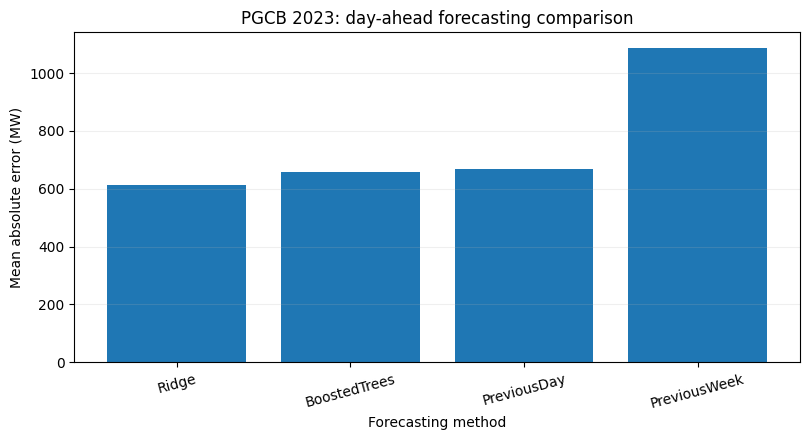

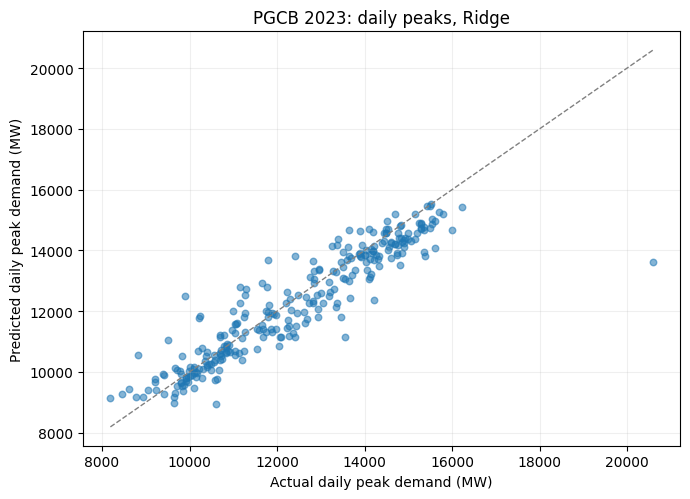

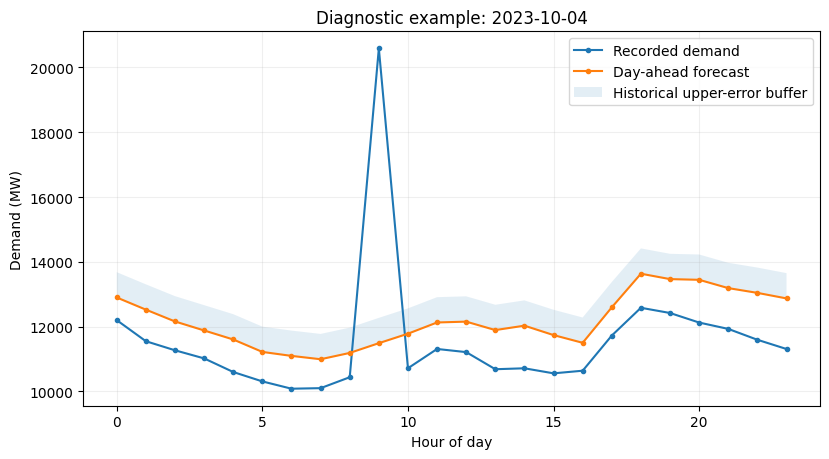

In [ ]:
fig, ax = plt.subplots(figsize=(8.2, 4.5))
ax.bar(validation_results['model'], validation_results['mae_mw'])
ax.set(title='PGCB 2023: day-ahead forecasting comparison',
       ylabel='Mean absolute error (MW)', xlabel='Forecasting method')
ax.grid(axis='y', alpha=0.20)
plt.xticks(rotation=15)
fig.tight_layout()
fig.savefig(OUT_DIR / 'figure_2023_forecast_mae.png', dpi=600)
plt.show()

fig, ax = plt.subplots(figsize=(7.0, 5.1))
ax.scatter(per_day['actual_peak_mw'], per_day['predicted_peak_mw'], alpha=0.55, s=22)
low = float(min(per_day[['actual_peak_mw','predicted_peak_mw']].min()))
high = float(max(per_day[['actual_peak_mw','predicted_peak_mw']].max()))
ax.plot([low, high], [low, high], linestyle='--', linewidth=1, color='gray')
ax.set(xlabel='Actual daily peak demand (MW)', ylabel='Predicted daily peak demand (MW)',
       title=f'PGCB 2023: daily peaks, {selected_name}')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_DIR / 'figure_2023_daily_peak_scatter.png', dpi=600)
plt.show()

worst_day = per_day.loc[per_day['abs_peak_error_mw'].idxmax(), 'date']
example = hourly_2023.loc[hourly_2023['date'].eq(worst_day)].copy()
fig, ax = plt.subplots(figsize=(8.4, 4.7))
ax.plot(example['hour'], example['actual_demand_mw'], marker='.', label='Recorded demand')
ax.plot(example['hour'], example['predicted_demand_mw'], marker='.', label='Day-ahead forecast')
ax.fill_between(example['hour'].to_numpy(dtype=float),
                example['predicted_demand_mw'].to_numpy(dtype=float),
                example['upper_demand_estimate_mw'].to_numpy(dtype=float),
                alpha=0.12, label='Historical upper-error buffer')
ax.set(xlabel='Hour of day', ylabel='Demand (MW)',
       title=f'Diagnostic example: {pd.Timestamp(worst_day).date()}')
ax.legend()
ax.grid(alpha=0.20)
fig.tight_layout()
fig.savefig(OUT_DIR / 'figure_2023_peak_error_example.png', dpi=600)
plt.show()


## 12. Save the model, audit trail and experiment outputs

The selected forecasting method, fixed feature names, calibration margin, chronological split, source checksum, software versions and results are packaged for later use in Phase 3 and for GitHub reviewer instructions.

**What this notebook does not do:** It does not create the original demand-optimization algorithm, apply consumer-level flexibility restrictions, or claim avoided load shedding. The next research notebook will use these forecasts in a clearly defined scheduling problem.

In [ ]:
model_bundle = {
    'method': selected_name,
    'estimator': refitted[selected_name],
    'features': FEATURES,
    'demand_screen_mw': [MIN_DEMAND_MW, MAX_DEMAND_MW],
    'fitted_through': '2022-06-30',
    'calibration_period': '2022-07-01 to 2022-12-31',
    'underprediction_buffer_q90_mw': underprediction_q90_mw,
    'source_sha256': source_sha256,
}
joblib.dump(model_bundle, OUT_DIR / 'forecast_model_bundle.joblib')

manifest = {
    'project_title': 'An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids',
    'phase': 'Phase 2: day-ahead demand forecasting (not proposed optimizer)',
    'run_id': RUN_ID,
    'source': {'name': 'PGCB Hourly Generation Dataset (Bangladesh)',
               'uci_doi': '10.24432/C59P6V', 'sha256': source_sha256,
               'source_file': DATA_PATH.name},
    'screening_rules': {'only_whole_hours': True, 'reject_duplicated_timestamps': True,
                         'require_complete_24h_days': True,
                         'demand_screen_mw': [MIN_DEMAND_MW, MAX_DEMAND_MW],
                         'generation_screen_mw': [MIN_GENERATION_MW, MAX_GENERATION_MW],
                         'required_day_lags': [1, 7]},
    'periods': {k: {'start': str(v['date'].min().date()),
                     'end': str(v['date'].max().date()),
                     'n_days': v['date'].nunique(), 'n_hours': len(v)}
                for k, v in periods.items()},
    'feature_names': FEATURES,
    'candidate_methods': list(CANDIDATES),
    'selection_rule': 'Minimum hourly MAE on January-June 2022; tie by fixed name',
    'selected_method': selected_name,
    'calibration_margin_q90_underprediction_mw': underprediction_q90_mw,
    'empirical_2023_upper_coverage_pct': upper_coverage,
    'software': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'sklearn': sklearn.__version__},
    'limitations': [
        '2024-2025 was previously inspected in Phase 1, and is not used here.',
        'Source data contains irregular timestamps and possible measurement errors.',
        'Day-ahead forecasts use only earlier-day historical loads and calendar features.',
        'The historical forecast-error buffer does not guarantee future coverage.',
        'No optimization or real-world load-shedding reduction is estimated in Phase 2.',
    ],
}
(OUT_DIR / 'phase2_reproducibility_manifest.json').write_text(json.dumps(manifest, indent=2))
archive_path = OUT_DIR / 'phase2_outputs.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for item in sorted(OUT_DIR.iterdir()):
        if item.is_file() and item != archive_path:
            archive.write(item, arcname=item.name)

expected = ['model_selection_2022_H1.csv', 'calibration_2022_H2.json',
            'forecast_comparison_2023.csv', 'hourly_forecasts_2023_selected.csv',
            'daily_forecast_metrics_2023.csv', 'forecast_model_bundle.joblib',
            'phase2_reproducibility_manifest.json', 'phase2_outputs.zip']
assert all((OUT_DIR / filename).exists() for filename in expected)
print('Phase 2 finished successfully.')
print('Selected forecast method:', selected_name)
print('2023 selected model MAE (MW):', round(float(validation_results.loc[
    validation_results['model'].eq(selected_name), 'mae_mw'].iloc[0]), 2))
print('Saved results to:', OUT_DIR)
print('Next phase: forecast-aware scheduling feasibility and proposed optimization design.')


Phase 2 finished successfully.
Selected forecast method: Ridge
2023 selected model MAE (MW): 614.32
Saved results to: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase2_20261107T083301Z_c5a9ca
Next phase: forecast-aware scheduling feasibility and proposed optimization design.
